# Tabular — Data Geospasial (latitude / longitude)
**Kapan dipakai:** data punya kolom koordinat (lintang/bujur), misalnya harga rumah,
lokasi toko, titik kejadian.

**Feature dari koordinat:**
- jarak (haversine, dalam km) ke kota penting;
- cluster lokasi (KMeans): wilayah yang berdekatan diberi nomor yang sama;
- kepadatan: jumlah titik lain dalam radius tertentu;
- koordinat diputar 45° dan 135° (membantu model pohon membuat batas miring).

Skor CV dibandingkan sebelum vs sesudah feature geospasial.

**Data demo:** California Housing (target `MedHouseVal`). Untuk Indonesia: ganti `CITIES` di
Konfigurasi (misalnya Jakarta -6.20, 106.85).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lightgbm import LGBMRegressor
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.neighbors import BallTree

## Konfigurasi

In [2]:
DATA_FOLDER = "Z:/GEMASTIK-DATABASE/data_latihan/tabular_extra/geo"   # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/california_train.csv"
TEST_CSV = f"{DATA_FOLDER}/california_test.csv"
TEST_KEY_CSV = f"{DATA_FOLDER}/california_test_labels.csv"   # hanya ada di data latihan

TARGET = "MedHouseVal"
ID_COL = "id"
LAT = "Latitude"
LON = "Longitude"
CITIES = {                       # nama kota: (lintang, bujur)
    "los_angeles": (34.05, -118.24),
    "san_francisco": (37.77, -122.42),
    "san_diego": (32.72, -117.16),
    "sacramento": (38.58, -121.49),
}
N_CLUSTERS = 20
RADIUS_KM = 5
EARTH_RADIUS_KM = 6371
SEED = 42

## Baca data

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
FEATURES = test.columns.drop(ID_COL).tolist()
print("train:", train.shape, "| test:", test.shape)
train.head()

train: (6000, 10) | test: (2000, 9)


,id,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,3836,4.6197,21.0,3.701933,1.019329,1489.0,1.514751,34.05,-118.46,3.875
1,6408,3.8750,32.0,6.528090,1.101124,563.0,3.162921,33.86,-118.00,2.030
2,4840,6.8742,25.0,5.900480,1.038369,1913.0,2.293765,37.88,-122.53,4.131
3,527,1.7427,32.0,4.757576,1.017128,2060.0,2.714097,40.69,-122.36,0.606
4,6105,3.7566,32.0,5.453390,1.125000,2609.0,5.527542,34.28,-118.41,1.467


## EDA: peta sebaran target
Warna = nilai target. Kalau warnanya mengelompok di wilayah tertentu, lokasi berpengaruh.

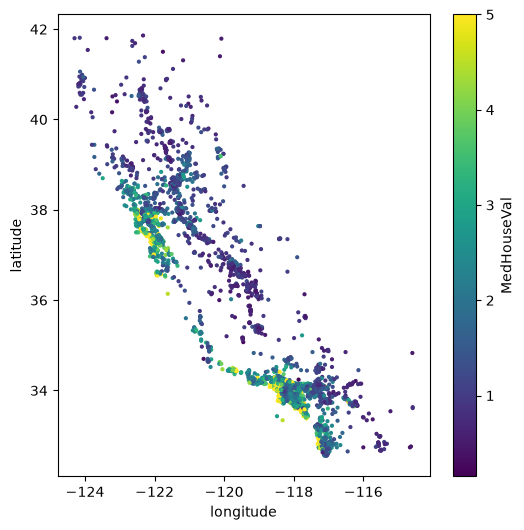

In [4]:
plt.figure(figsize=(6, 6))
plt.scatter(train[LON], train[LAT], c=train[TARGET], s=4, cmap="viridis")
plt.colorbar(label=TARGET)
plt.xlabel("longitude")
plt.ylabel("latitude")
plt.show()

## Jarak haversine
Jarak dua titik di permukaan bumi (km). Sudut harus diubah ke radian dulu.

In [5]:
def haversine(lat1, lon1, lat2, lon2):
    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)
    part = np.sin((lat2 - lat1) / 2) ** 2
    part = part + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return EARTH_RADIUS_KM * 2 * np.arcsin(np.sqrt(part))


# coba: Los Angeles ke San Francisco (sekitar 560 km)
print("LA - SF:", round(haversine(34.05, -118.24, 37.77, -122.42)), "km")

LA - SF: 559 km


## Feature geospasial
KMeans dan BallTree dilatih dari koordinat TRAIN, lalu dipakai juga untuk test.

In [6]:
kmeans = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=SEED)
kmeans.fit(train[[LAT, LON]])
tree = BallTree(np.radians(train[[LAT, LON]]), metric="haversine")


def add_features(table):
    table = table.copy()
    distance_cols = []
    for city in CITIES:
        city_lat = CITIES[city][0]
        city_lon = CITIES[city][1]
        table["jarak_" + city] = haversine(table[LAT], table[LON], city_lat, city_lon)
        distance_cols.append("jarak_" + city)
    table["jarak_kota_terdekat"] = table[distance_cols].min(axis=1)
    table["cluster_lokasi"] = kmeans.predict(table[[LAT, LON]])
    coordinates = np.radians(table[[LAT, LON]])
    table["kepadatan"] = tree.query_radius(coordinates, r=RADIUS_KM / EARTH_RADIUS_KM,
                                           count_only=True)
    table["putar_45"] = table[LAT] + table[LON]
    table["putar_135"] = table[LAT] - table[LON]
    return table


train_fe = add_features(train)
test_fe = add_features(test)
NEW_FEATURES = test_fe.columns.drop(ID_COL).tolist()
added_cols = NEW_FEATURES[len(FEATURES):]
train_fe[added_cols].describe().round(2)

,jarak_los_angeles,jarak_san_francisco,jarak_san_diego,jarak_sacramento,jarak_kota_terdekat,cluster_lokasi,kepadatan,putar_45,putar_135
count,6000.00,6000.00,6000.00,6000.00,6000.00,6000.00,6000.00,6000.00,6000.00
mean,265.69,392.08,390.45,411.91,65.37,8.11,31.68,-83.94,155.10
std,245.84,251.17,289.36,248.58,71.39,6.55,26.96,0.81,4.07
min,0.92,0.88,0.94,0.00,0.00,0.00,1.00,-85.89,147.39
25%,31.78,120.05,157.31,134.59,17.54,1.00,10.00,-84.42,151.92
50%,172.79,530.16,208.87,554.18,37.62,7.00,26.00,-84.19,152.70
75%,522.94,586.02,701.00,606.75,81.21,16.00,47.00,-83.56,159.52
max,1011.85,899.72,1190.04,895.45,430.25,19.00,146.00,-78.29,166.10


## Model
Pilih SATU model: hapus `#` di baris yang ingin dipakai, beri `#` pada baris lain.

In [7]:
model = LGBMRegressor(n_estimators=600, learning_rate=0.03, random_state=SEED, verbose=-1)
# model = RandomForestRegressor(n_estimators=400, min_samples_leaf=2, random_state=SEED, n_jobs=-1)
# model = LGBMRegressor(n_estimators=1200, learning_rate=0.02, num_leaves=63, verbose=-1)

## Evaluasi: CV 5-fold sebelum vs sesudah feature geospasial
RMSE makin kecil makin bagus.

In [8]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
y = train_fe[TARGET]
scores_before = -cross_val_score(model, train_fe[FEATURES], y, cv=cv,
                                 scoring="neg_root_mean_squared_error")
scores_after = -cross_val_score(model, train_fe[NEW_FEATURES], y, cv=cv,
                                scoring="neg_root_mean_squared_error")
print("RMSE CV tanpa feature geo :", round(scores_before.mean(), 4))
print("RMSE CV dengan feature geo:", round(scores_after.mean(), 4))

X_train, X_val, y_train, y_val = train_test_split(train_fe[NEW_FEATURES], y,
                                                  test_size=0.2, random_state=SEED)
model.fit(X_train, y_train)
val_predictions = model.predict(X_val)
print("RMSE validasi:", round(root_mean_squared_error(y_val, val_predictions), 4))

RMSE CV tanpa feature geo : 0.4901
RMSE CV dengan feature geo: 0.4648


RMSE validasi: 0.4416


## Latih ulang di semua data + submission

In [9]:
model.fit(train_fe[NEW_FEATURES], y)
predictions = model.predict(test_fe[NEW_FEATURES])

submission = pd.DataFrame()
submission["id"] = test["id"]
submission["MedHouseVal"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

,id,MedHouseVal
0,2215,3.851110
1,2582,2.938447
2,1662,2.473820
3,3027,1.842811
4,4343,1.599560


## Cek dengan kunci jawaban latihan
**HAPUS sel ini saat lomba**: file kunci hanya ada di data latihan.

In [10]:
test_key = pd.read_csv(TEST_KEY_CSV)["MedHouseVal"]
print("RMSE test (kunci latihan):", round(root_mean_squared_error(test_key, predictions), 4))

RMSE test (kunci latihan): 0.4584
